<a href="https://colab.research.google.com/github/trishnanika/food-waste-prediction-clustering/blob/main/Food_Waste_Prediction%26Clustering_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Food Waste Prediction and Clustering Analysis

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

# Load train.csv
train_df = pd.read_csv('/content/drive/MyDrive/train.csv')
print('train.csv loaded successfully:')
display(train_df.head())

train.csv loaded successfully:


,ID,date,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,food_waste_kg
0,0,2022-12-19,196,13,27.887273,45.362854,0,0,7.740587,intermediate,dairy,28.946465
1,1,2023-11-21,244,15,10.317872,64.430475,1,0,42.311779,NaN,MeAt,51.549053
2,4,2022-02-01,148,16,27.714300,69.046113,1,0,41.184305,Beginner,MeAt,53.008323
3,5,2023-03-19,157,19,19.173902,46.292823,6,0,41.543492,Beginner,MeAt,48.621527
4,6,2022-07-18,297,10,26.375233,79.741064,0,0,26.525097,Intermediate,MEAT,44.156984


In [ ]:
# Load test.csv

test_df = pd.read_csv('/content/drive/MyDrive/test.csv')
print('\ntest.csv loaded successfully:')
display(test_df.head())


test.csv loaded successfully:


,ID,date,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category
0,0,2022-12-19,196,13,27.887273,45.362854,0,0,7.740587,intermediate,dairy
1,1,2023-11-21,244,15,10.317872,64.430475,1,0,42.311779,NaN,MeAt
2,4,2022-02-01,148,16,27.714300,69.046113,1,0,41.184305,Beginner,MeAt
3,5,2023-03-19,157,19,19.173902,46.292823,6,0,41.543492,Beginner,MeAt
4,6,2022-07-18,297,10,26.375233,79.741064,0,0,26.525097,Intermediate,MEAT


In [ ]:
# For Analysis and Visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# For Preprocessing & Data Splitting
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split

# Regression Models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor  # optional

# Evaluation Metrics (Regression)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Ignore Warnings
import warnings
warnings.filterwarnings('ignore')

**Dataset information**

In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 911 entries, 0 to 910
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                911 non-null    int64  
 1   date              911 non-null    object 
 2   meals_served      911 non-null    int64  
 3   kitchen_staff     911 non-null    int64  
 4   temperature_C     911 non-null    float64
 5   humidity_percent  911 non-null    float64
 6   day_of_week       911 non-null    int64  
 7   special_event     911 non-null    int64  
 8   past_waste_kg     911 non-null    float64
 9   staff_experience  747 non-null    object 
 10  waste_category    911 non-null    object 
 11  food_waste_kg     911 non-null    float64
dtypes: float64(4), int64(5), object(3)
memory usage: 85.5+ KB


In [ ]:
print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(train_df.shape,train_df.shape[0],train_df.shape[1]))

Shape of the dataset is (911, 12). This dataset contains 911 rows and 12 columns.


## 1. Data Loading and Initial Inspection

**Data Splitting**

In [ ]:
##Selecting numerical features
numerical_data = train_df.select_dtypes(include='number')

#append the features of numerical_data to list
numerical_features=numerical_data.columns.tolist()

print(f'There are {len(numerical_features)} numerical features:', '\n')
print(numerical_features)

There are 9 numerical features: 

['ID', 'meals_served', 'kitchen_staff', 'temperature_C', 'humidity_percent', 'day_of_week', 'special_event', 'past_waste_kg', 'food_waste_kg']


In [ ]:
#Selecting categoricalfeatures
categorical_data=train_df.select_dtypes(include= 'object')

#append the features of categorical_data to list
categorical_features=categorical_data.columns.tolist()

print(f'There are {len(categorical_features)} categorical features:', '\n')
print(categorical_features)

There are 3 categorical features: 

['date', 'staff_experience', 'waste_category']


## 2. Exploratory Data Analysis (EDA)

**Descriptive Analysis**

In [ ]:
# Transposed stats for numerical features
numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,911.0,528.327113,305.072794,0.000000,266.000000,531.000000,795.500000,1049.000000
meals_served,911.0,375.405049,502.812717,100.000000,211.000000,306.000000,407.000000,4730.000000
kitchen_staff,911.0,11.900110,4.285153,5.000000,8.000000,12.000000,15.000000,19.000000
temperature_C,911.0,22.189280,8.922389,-10.372207,15.684585,22.115040,28.804294,60.000000
humidity_percent,911.0,60.761313,17.330821,30.121111,46.017835,61.633960,75.787910,89.982828
day_of_week,911.0,3.014270,2.009542,0.000000,1.000000,3.000000,5.000000,6.000000
special_event,911.0,0.085620,0.279956,0.000000,0.000000,0.000000,0.000000,1.000000
past_waste_kg,911.0,27.015691,12.774223,5.008394,16.091383,26.854109,38.149878,49.803703
food_waste_kg,911.0,44.842691,27.934366,10.819048,32.887912,41.146930,50.046681,274.328783


In [ ]:
#Variance of each numerical features
numerical_data.var()

,0
ID,93069.409363
meals_served,252820.628062
kitchen_staff,18.362538
temperature_C,79.609032
humidity_percent,300.357363
day_of_week,4.038258
special_event,0.078375
past_waste_kg,163.180761
food_waste_kg,780.328817


In [ ]:
#Skewness
numerical_data.skew()

,0
ID,-0.015749
meals_served,6.581128
kitchen_staff,0.020202
temperature_C,0.111854
humidity_percent,-0.093234
day_of_week,-0.008186
special_event,2.966833
past_waste_kg,0.016268
food_waste_kg,4.990900


In [ ]:
# Transposed stats for categorical features

categorical_data.describe().T

,count,unique,top,freq
date,911,867,2022-02-02,2
staff_experience,747,4,Beginner,191
waste_category,911,5,MEAT,210


**Histogram on numerical data**

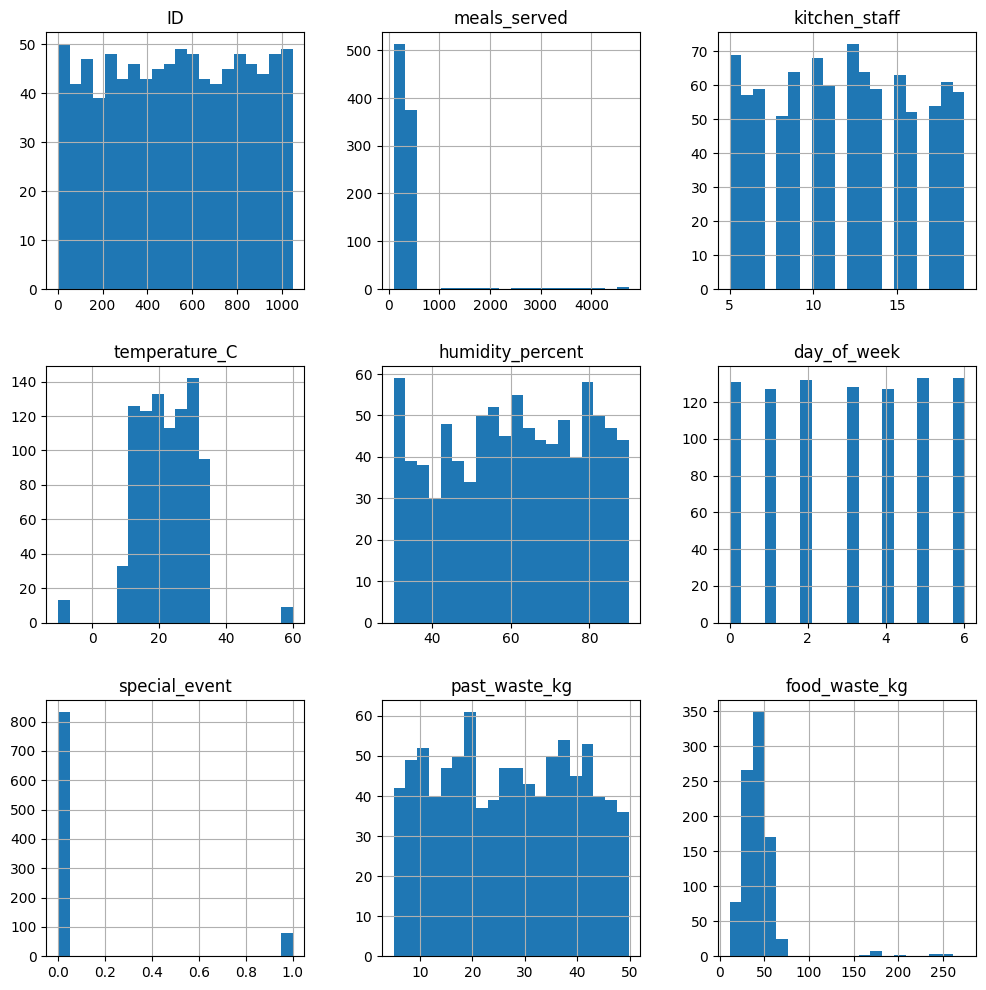

In [ ]:
numerical_data.hist(figsize=(12,12),bins=20)
plt.show()

**Boxplot on numerical data**

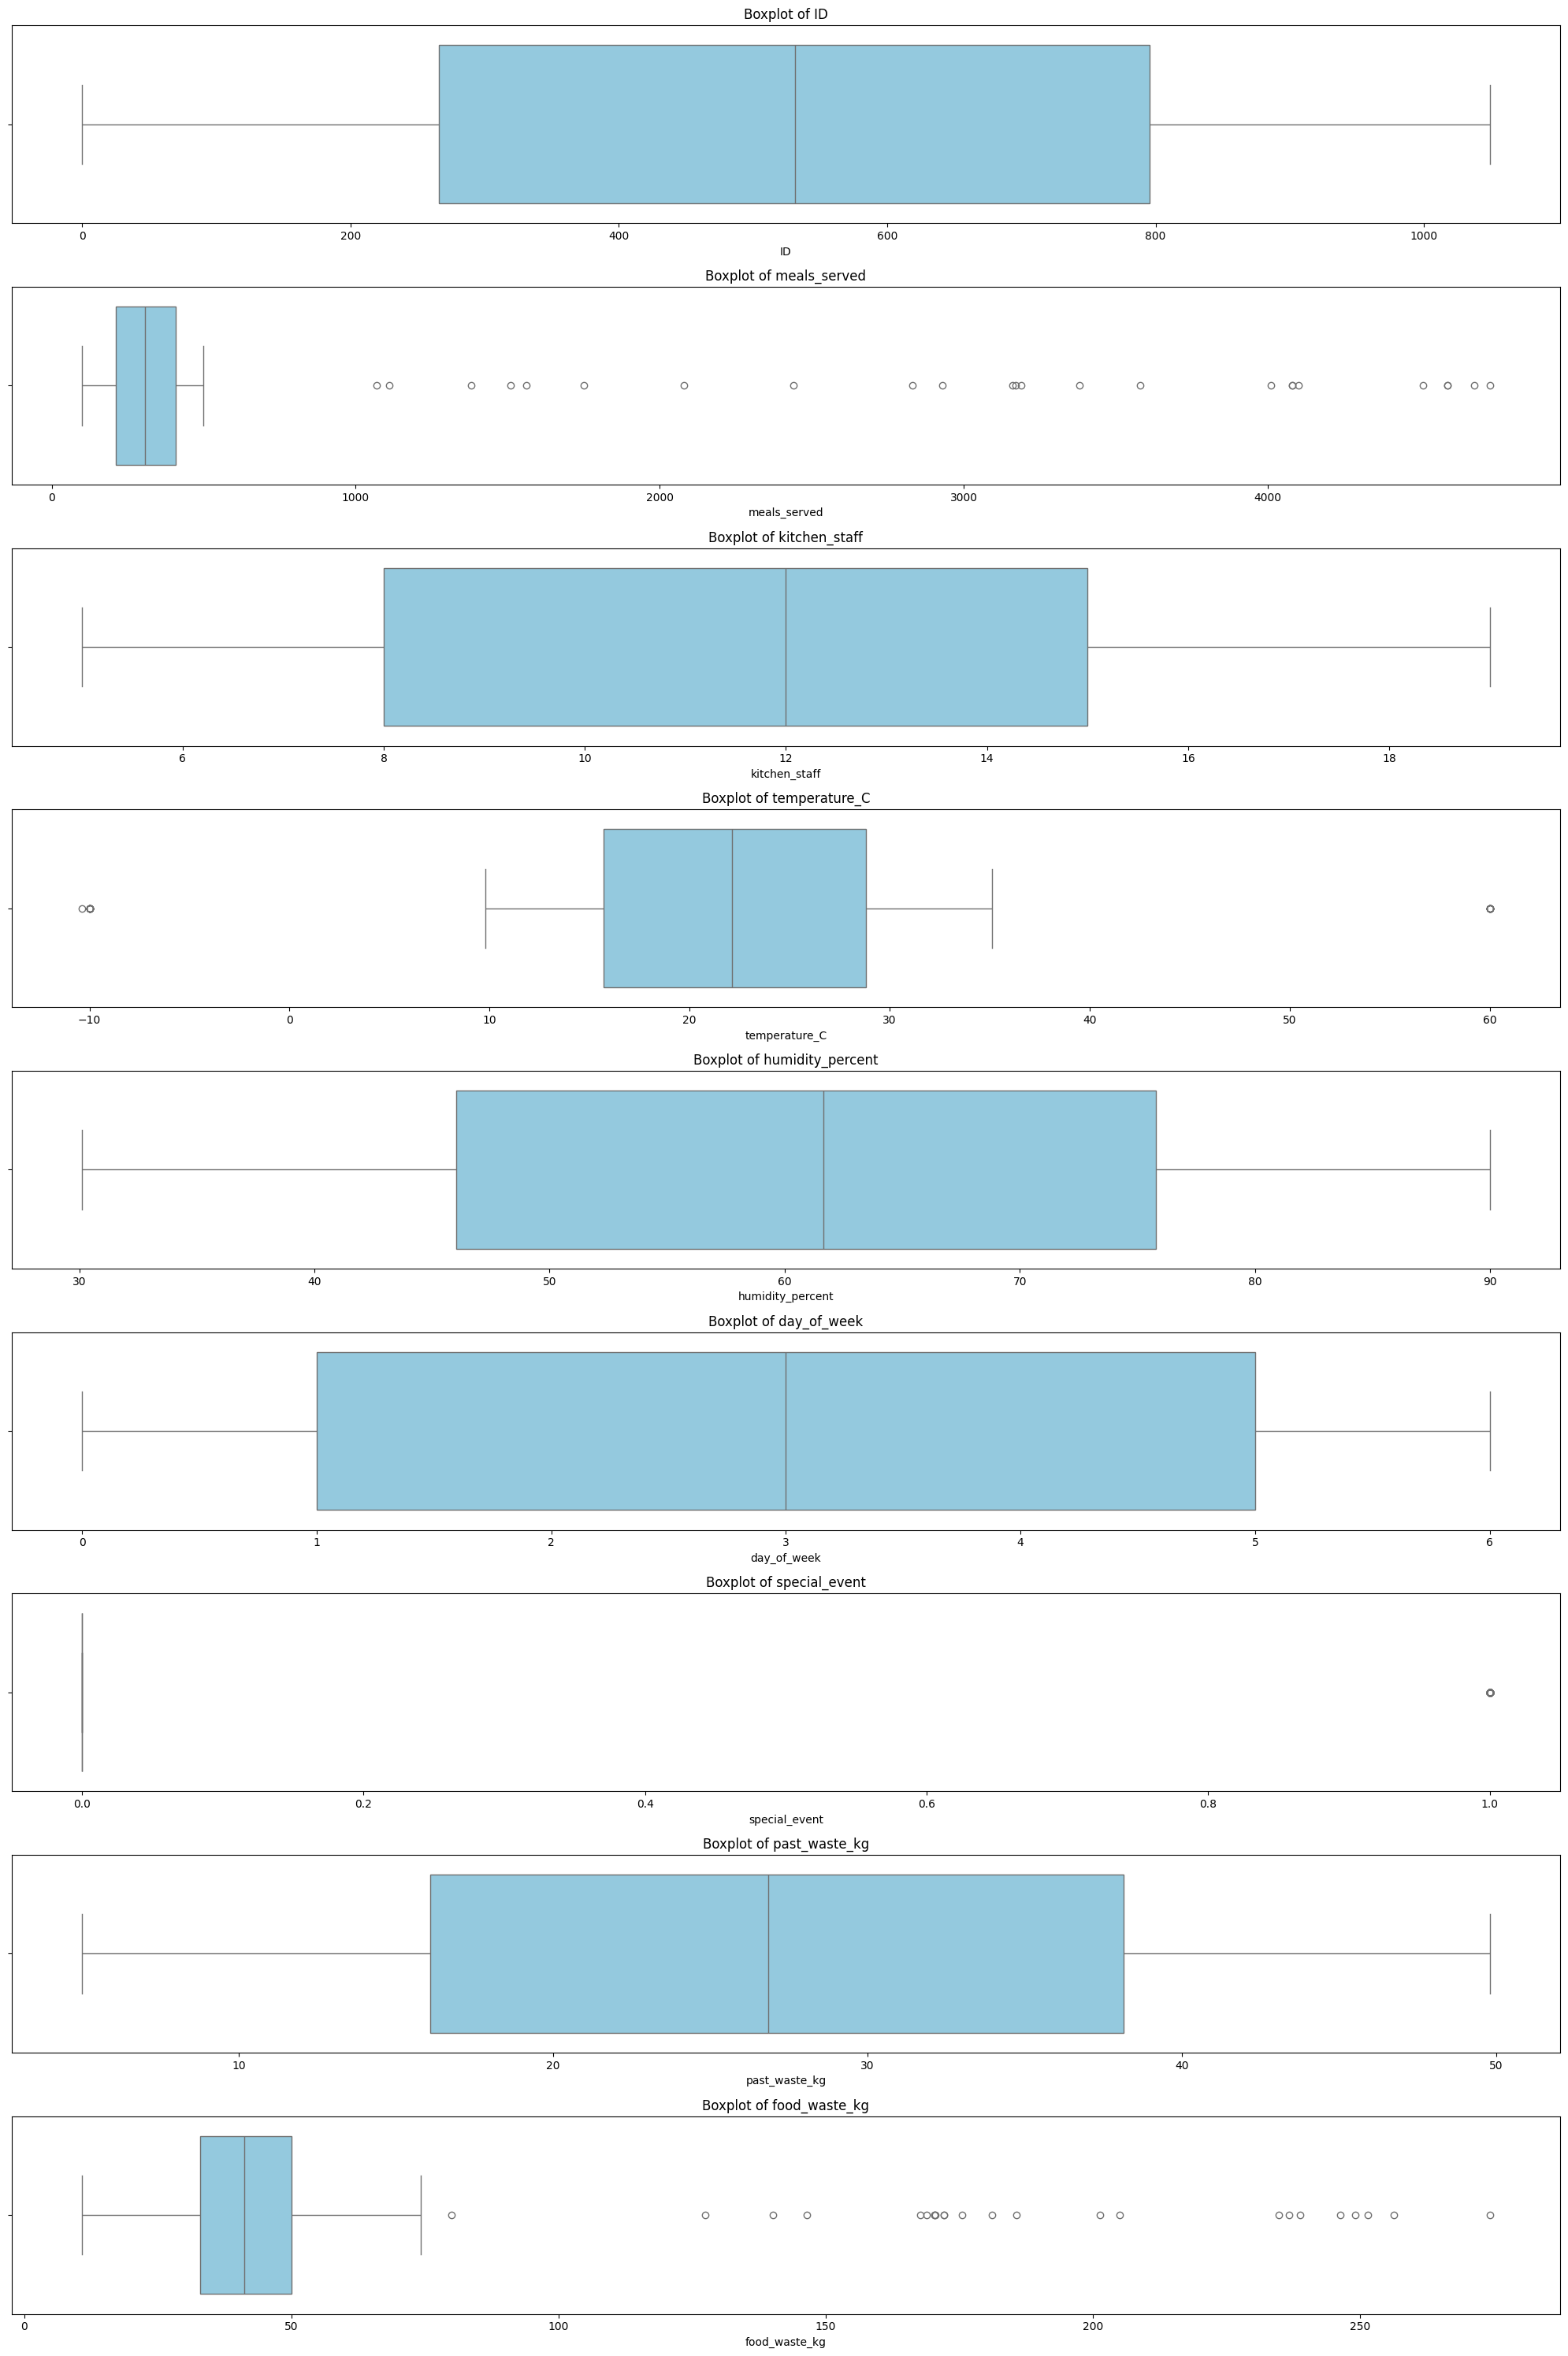

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns for boxplot analysis
numeric_cols = train_df.select_dtypes(include=['int64', 'float64']).columns

# Set up the figure
plt.figure(figsize=(20, 30))

# Plot boxplots for each numerical feature including the target variable 'OUTCOME'
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x=train_df[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()

plt.show()

In [ ]:
#Unique values
numerical_data.nunique()

,0
ID,911
meals_served,373
kitchen_staff,15
temperature_C,892
humidity_percent,867
day_of_week,7
special_event,2
past_waste_kg,867
food_waste_kg,867


In [ ]:
# unique values counts
unique_counts=categorical_data.nunique()
print(unique_counts)

date                867
staff_experience      4
waste_category        5
dtype: int64


**Barplot for categorical values**

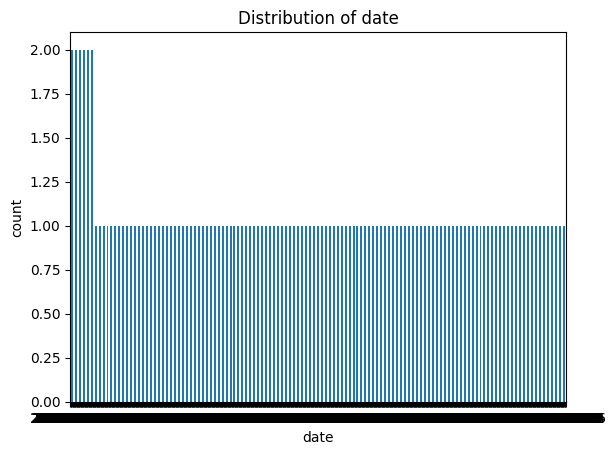

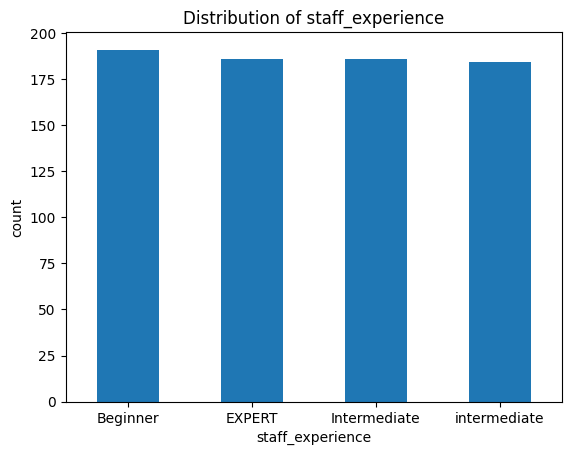

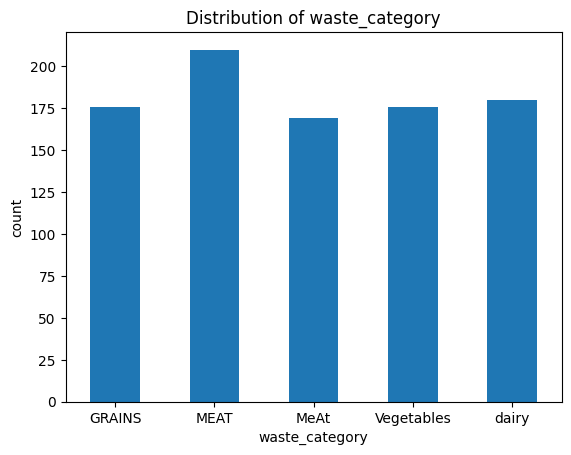

In [ ]:
for col in categorical_features:
    plt.title(f'Distribution of {col}')
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=0, xlabel=col,ylabel='count')
    plt.show()

## 3. Data Preprocessing

**EDA on training data**

 **Null values**

In [ ]:
train_df.isnull().sum()

,0
ID,0
date,0
meals_served,0
kitchen_staff,0
temperature_C,0
humidity_percent,0
day_of_week,0
special_event,0
past_waste_kg,0
staff_experience,164


In [ ]:
# Drop rows where 'staff_experience' is NaN
train_df = train_df.dropna(subset=['staff_experience'])

# Verify that no missing values remain in that column
print(train_df['staff_experience'].isnull().sum())

0


In [ ]:
# Convert both columns to lowercase
train_df['staff_experience'] = train_df['staff_experience'].str.lower()
train_df['waste_category']   = train_df['waste_category'].str.lower()

train_df.head()

,ID,date,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,food_waste_kg
0,0,2022-12-19,196,13,27.887273,45.362854,0,0,7.740587,intermediate,dairy,28.946465
2,4,2022-02-01,148,16,27.714300,69.046113,1,0,41.184305,beginner,meat,53.008323
3,5,2023-03-19,157,19,19.173902,46.292823,6,0,41.543492,beginner,meat,48.621527
4,6,2022-07-18,297,10,26.375233,79.741064,0,0,26.525097,intermediate,meat,44.156984
5,7,2023-03-02,241,18,16.863506,79.285919,3,0,11.834878,intermediate,dairy,27.393670


In [ ]:
#check unique values after cleaning
print(train_df['staff_experience'].unique())
print(train_df['waste_category'].unique())

['intermediate' 'beginner' 'expert']
['dairy' 'meat' 'vegetables' 'grains']


In [ ]:
train_df['staff_experience'] = train_df['staff_experience'].map({'intermediate':1,'beginner':2,'expert':3})
train_df['waste_category'] = train_df['waste_category'].map({'dairy':1,'meat':2,'vegetables':3,'grains':4})

train_df.head()

,ID,date,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,food_waste_kg
0,0,2022-12-19,196,13,27.887273,45.362854,0,0,7.740587,1,1,28.946465
2,4,2022-02-01,148,16,27.714300,69.046113,1,0,41.184305,2,2,53.008323
3,5,2023-03-19,157,19,19.173902,46.292823,6,0,41.543492,2,2,48.621527
4,6,2022-07-18,297,10,26.375233,79.741064,0,0,26.525097,1,2,44.156984
5,7,2023-03-02,241,18,16.863506,79.285919,3,0,11.834878,1,1,27.393670


**Scalling**

In [ ]:
# Convert to datetime
train_df['date'] = pd.to_datetime(train_df['date'])

# Extract useful parts
train_df['year'] = train_df['date'].dt.year
train_df['month'] = train_df['date'].dt.month

# Drop the original date and ID not needed
train_df.drop(columns=['date'], inplace=True)
train_df.drop(columns=['ID'], inplace=True)

# scaling
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Example: assume your dataset is in train_df
scaler = StandardScaler()

# Scale all numeric columns
scaled_data = scaler.fit_transform(train_df)

# Convert back to DataFrame with same column names
train_df = pd.DataFrame(scaled_data, columns=train_df.columns)

train_df.head()

,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,food_waste_kg,year,month
0,-0.356622,0.251520,0.620850,-0.869865,-1.469557,-0.311314,-1.500514,-0.911538,-1.363084,-0.572256,-1.084805,1.831945
1,-0.444171,0.947392,0.601953,0.497817,-0.975516,-0.311314,1.097254,0.297909,-0.367753,0.249950,-1.084805,-1.154661
2,-0.427755,1.643263,-0.331051,-0.816160,1.494689,-0.311314,1.125154,0.297909,-0.367753,0.100051,0.163807,-0.856000
3,-0.172405,-0.444352,0.455666,1.115439,-1.469557,-0.311314,-0.041412,-0.911538,-0.367753,-0.052505,-1.084805,0.338642
4,-0.274545,1.411306,-0.583452,1.089155,0.012566,-0.311314,-1.182487,-0.911538,-1.363084,-0.625316,0.163807,-0.856000


In [ ]:
# Features (drop the label column)
train_df_x = train_df.drop(columns=['food_waste_kg'])

# Label (target variable)
train_df_y = train_df['food_waste_kg']


## 4. Model Training and Evaluation

**Correlation Analysis**

In [ ]:
# Calculate the correlation matrix
correlation_matrix = numerical_data.corr()
correlation_matrix

,ID,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,food_waste_kg
ID,1.000000,-0.012605,-0.028697,0.047744,0.002652,0.028893,0.005462,0.039278,-0.020233
meals_served,-0.012605,1.000000,-0.028022,-0.019706,-0.041477,0.026719,-0.000387,-0.063700,0.852128
kitchen_staff,-0.028697,-0.028022,1.000000,-0.020965,-0.021430,0.034494,-0.001107,-0.079861,0.007192
temperature_C,0.047744,-0.019706,-0.020965,1.000000,-0.011916,0.021189,-0.006800,-0.021711,-0.015911
humidity_percent,0.002652,-0.041477,-0.021430,-0.011916,1.000000,0.015120,0.018948,0.016266,-0.021793
day_of_week,0.028893,0.026719,0.034494,0.021189,0.015120,1.000000,-0.041240,0.000472,0.008090
special_event,0.005462,-0.000387,-0.001107,-0.006800,0.018948,-0.041240,1.000000,0.009663,0.118757
past_waste_kg,0.039278,-0.063700,-0.079861,-0.021711,0.016266,0.000472,0.009663,1.000000,0.260767
food_waste_kg,-0.020233,0.852128,0.007192,-0.015911,-0.021793,0.008090,0.118757,0.260767,1.000000


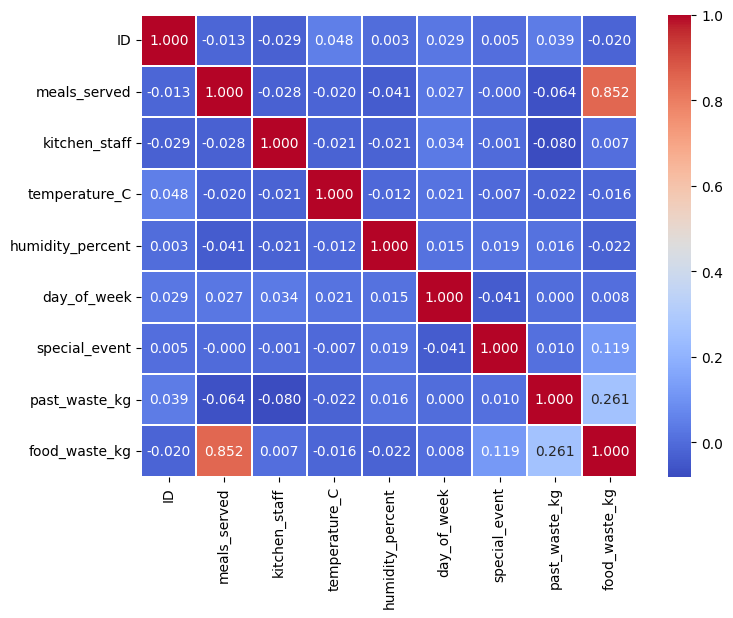

In [ ]:
# Plotting the heatmap for correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.3f', linewidths=0.3)
plt.show()

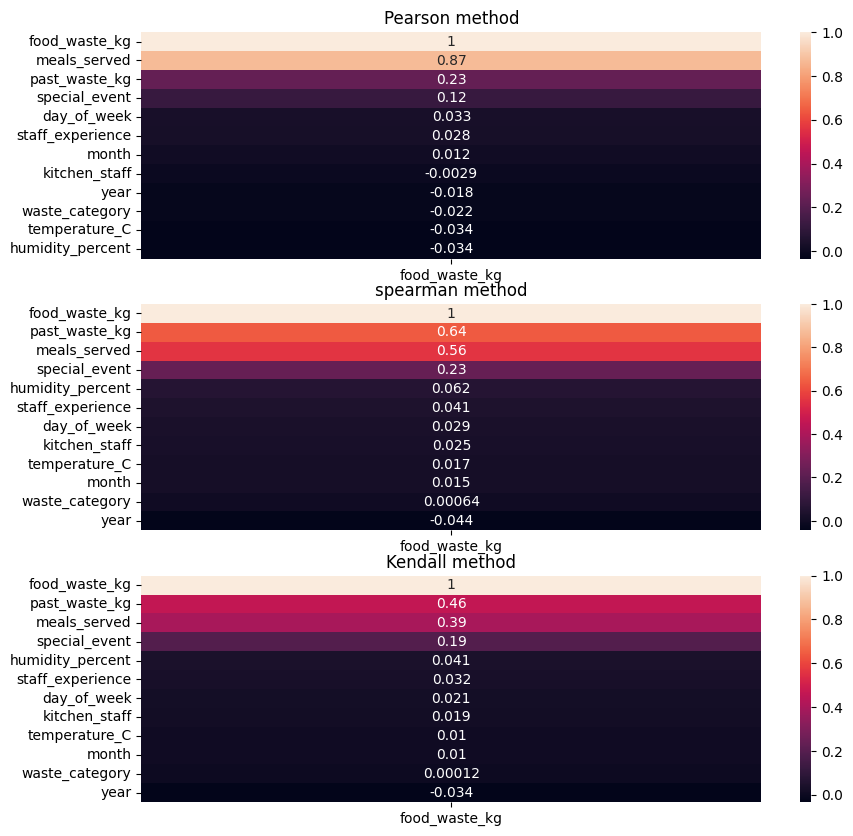

In [ ]:
fig, ax = plt.subplots(3,1, figsize=(10, 10))
## Correlation coefficient using different methods
corr1 = train_df.corr('pearson')[['food_waste_kg']].sort_values(by='food_waste_kg', ascending=False)
corr2 = train_df.corr('spearman')[['food_waste_kg']].sort_values(by='food_waste_kg', ascending=False)
corr3 = train_df.corr('kendall')[['food_waste_kg']].sort_values(by='food_waste_kg', ascending=False)

#setting titles for each plot
ax[0].set_title('Pearson method')
ax[1].set_title('spearman method')
ax[2].set_title('Kendall method')

## Generating heatmaps of each methods
sns.heatmap(corr1, ax=ax[0], annot=True)
sns.heatmap(corr2, ax=ax[1], annot=True)
sns.heatmap(corr3, ax=ax[2], annot=True)

plt.show()

**Density Plot for numerical data**

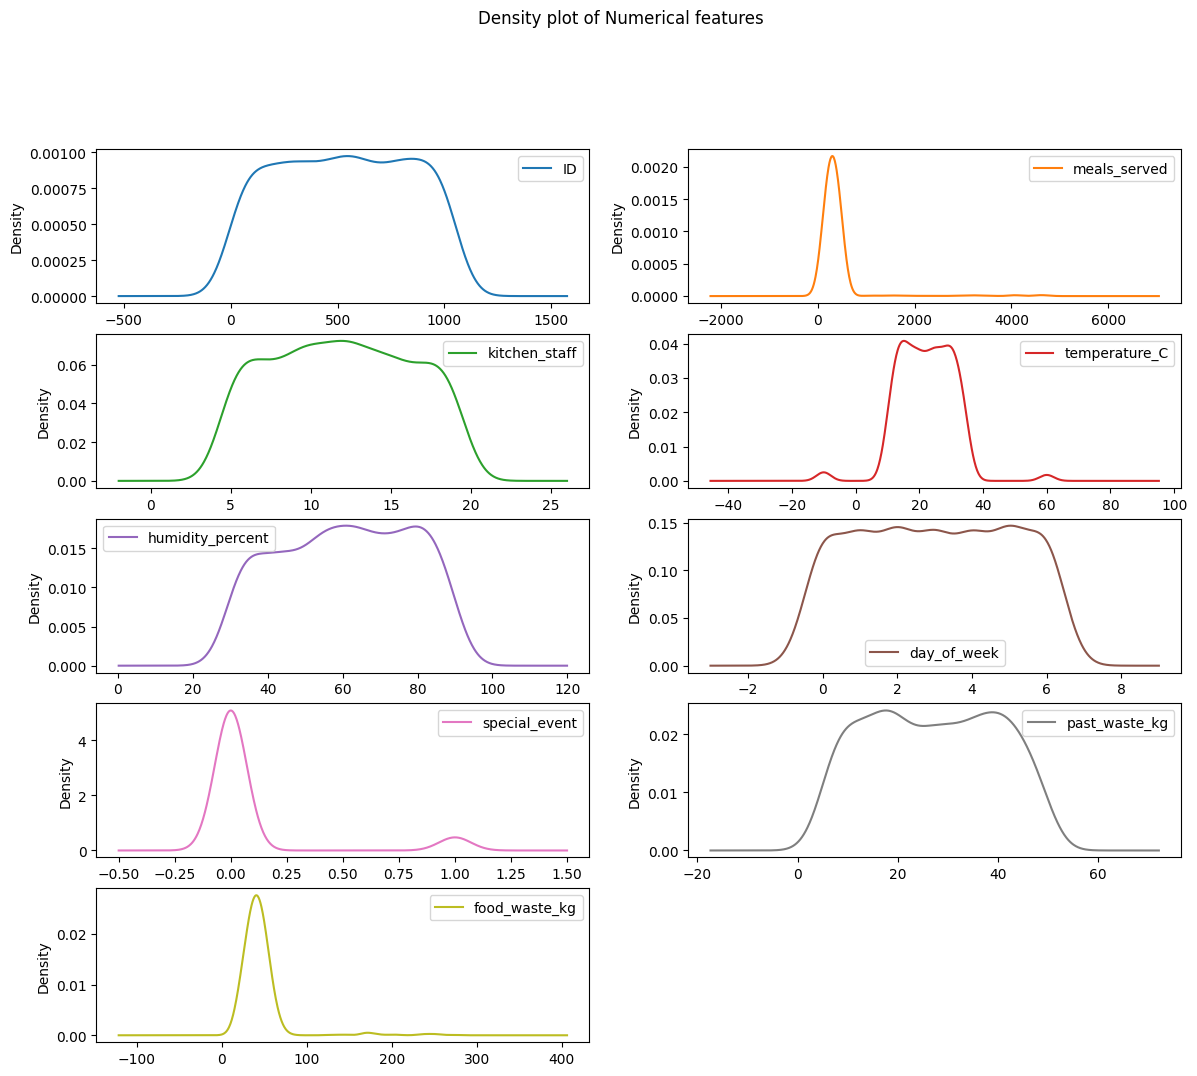

In [ ]:
numerical_data.plot(kind='density',figsize=(14,14),subplots=True,layout=(6,2),title="Density plot of Numerical features",sharex=False)
plt.show()

,proportion
food_waste_kg,
0.166586,0.002677
4.259498,0.002677
-0.024683,0.002677
0.264722,0.002677
-0.775897,0.002677
...,...
0.302199,0.001339
-0.372848,0.001339
0.221376,0.001339


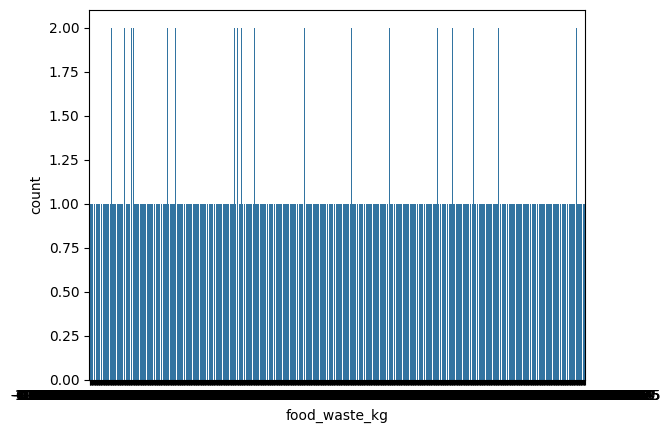

In [ ]:
sns.countplot(x='food_waste_kg', data=train_df)
train_df['food_waste_kg'].value_counts(normalize=True)

**Feature Relationships**

<Axes: xlabel='waste_category', ylabel='food_waste_kg'>

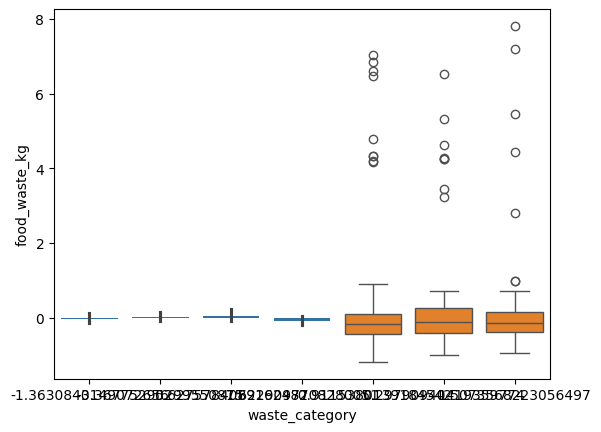

In [ ]:
sns.barplot(x='waste_category', y='food_waste_kg', data=train_df)
sns.boxplot(x='staff_experience', y='food_waste_kg', data=train_df)

**Test Data Preprocessing**

In [ ]:
test_df_y = pd.read_csv('/content/drive/MyDrive/submission.csv')
test_df_y.drop(columns=['ID'], inplace=True)
test_df_y.head()



,food_waste_kg
0,28.946465
1,51.549053
2,53.008323
3,48.621527
4,44.156984


In [ ]:
test_df_x = test_df.dropna(subset=['staff_experience']).copy()

test_df_y_aligned = test_df_y.loc[test_df_x.index, 'food_waste_kg']

test_df_x["food_waste_kg"] = test_df_y_aligned.values

# Apply string manipulations and mappings for categorical features
test_df_x['staff_experience'] = test_df_x['staff_experience'].str.lower()
test_df_x['waste_category']   = test_df_x['waste_category'].str.lower()

test_df_x['staff_experience'] = test_df_x['staff_experience'].map({'intermediate':1,'beginner':2,'expert':3})
test_df_x['waste_category'] = test_df_x['waste_category'].map({'dairy':1,'meat':2,'vegetables':3,'grains':4})

# Convert 'date' to datetime and extract 'year' and 'month'
test_df_x['date'] = pd.to_datetime(test_df_x['date'])
test_df_x['year'] = test_df_x['date'].dt.year
test_df_x['month'] = test_df_x['date'].dt.month

# Drop the original 'date' and 'ID' columns as they are no longer needed for modeling
test_df_x.drop(columns=['date', 'ID'], inplace=True)

# Scale the test data using the scaler fitted on the training data.
# It's important that `test_df_x` has the same columns in the same order as the
# training data (`train_df`) did when the `scaler` was fitted.
scaled_test_data = scaler.transform(test_df_x)
test_df_x = pd.DataFrame(scaled_test_data, columns=test_df_x.columns)

test_df_x.head()


,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,food_waste_kg,year,month
0,-0.356622,0.251520,0.620850,-0.869865,-1.469557,-0.311314,-1.500514,-0.911538,-1.363084,-0.572256,-1.084805,1.831945
1,-0.444171,0.947392,0.601953,0.497817,-0.975516,-0.311314,1.097254,0.297909,-0.367753,0.249950,-1.084805,-1.154661
2,-0.427755,1.643263,-0.331051,-0.816160,1.494689,-0.311314,1.125154,0.297909,-0.367753,0.100051,0.163807,-0.856000
3,-0.172405,-0.444352,0.455666,1.115439,-1.469557,-0.311314,-0.041412,-0.911538,-0.367753,-0.052505,-1.084805,0.338642
4,-0.274545,1.411306,-0.583452,1.089155,0.012566,-0.311314,-1.182487,-0.911538,-1.363084,-0.625316,0.163807,-0.856000


In [ ]:
# Label (target variable)
test_df_y = test_df_x['food_waste_kg']
test_df_y.head()
# Features (drop the label column)
test_df_x = test_df_x.drop(columns=['food_waste_kg'])
test_df_x.head()

,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,year,month
0,-0.356622,0.251520,0.620850,-0.869865,-1.469557,-0.311314,-1.500514,-0.911538,-1.363084,-1.084805,1.831945
1,-0.444171,0.947392,0.601953,0.497817,-0.975516,-0.311314,1.097254,0.297909,-0.367753,-1.084805,-1.154661
2,-0.427755,1.643263,-0.331051,-0.816160,1.494689,-0.311314,1.125154,0.297909,-0.367753,0.163807,-0.856000
3,-0.172405,-0.444352,0.455666,1.115439,-1.469557,-0.311314,-0.041412,-0.911538,-0.367753,-1.084805,0.338642
4,-0.274545,1.411306,-0.583452,1.089155,0.012566,-0.311314,-1.182487,-0.911538,-1.363084,0.163807,-0.856000


### Linear Regression Model

In [ ]:
# Initialize the Linear Regression model
linear_model = LinearRegression()

# Train the model
linear_model.fit(train_df_x, train_df_y)

print("Linear Regression model training complete.")

Linear Regression model training complete.


In [ ]:
# Make predictions on the test set using Linear Regression
y_pred_linear = linear_model.predict(test_df_x)

# Evaluate the Linear Regression model
mae_linear = mean_absolute_error(test_df_y, y_pred_linear)
mse_linear = mean_squared_error(test_df_y, y_pred_linear)
r2_linear = r2_score(test_df_y, y_pred_linear)

print(f"Linear Regression Mean Absolute Error (MAE): {mae_linear:.4f}")
print(f"Linear Regression Mean Squared Error (MSE): {mse_linear:.4f}")
print(f"Linear Regression R-squared (R2): {r2_linear:.4f}")

Linear Regression Mean Absolute Error (MAE): 0.1846
Linear Regression Mean Squared Error (MSE): 0.1388
Linear Regression R-squared (R2): 0.8612


### Random Forest Regressor Model

In [ ]:
# Initialize the RandomForestRegressor model
rf_model = RandomForestRegressor(random_state=42)

# Train the model
rf_model.fit(train_df_x, train_df_y)

print("Random Forest Regressor model training complete.")

Random Forest Regressor model training complete.


In [ ]:
# Make predictions on the test set using Random Forest
y_pred_rf = rf_model.predict(test_df_x)

# Evaluate the Random Forest model
mae_rf = mean_absolute_error(test_df_y, y_pred_rf)
mse_rf = mean_squared_error(test_df_y, y_pred_rf)
r2_rf = r2_score(test_df_y, y_pred_rf)

print(f"Random Forest Mean Absolute Error (MAE): {mae_rf:.4f}")
print(f"Random Forest Mean Squared Error (MSE): {mse_rf:.4f}")
print(f"Random Forest R-squared (R2): {r2_rf:.4f}")

Random Forest Mean Absolute Error (MAE): 0.0624
Random Forest Mean Squared Error (MSE): 0.0112
Random Forest R-squared (R2): 0.9888


### Comparison of Models

In [ ]:
comparison_data = {
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE': [mae_linear, mae_rf],
    'MSE': [mse_linear, mse_rf],
    'R2': [r2_linear, r2_rf]
}
comparison_df = pd.DataFrame(comparison_data)
display(comparison_df)

,Model,MAE,MSE,R2
0,Linear Regression,0.184622,0.138845,0.861155
1,Random Forest,0.062383,0.011189,0.988811


### Neural Network (MLP Regressor) Model

In [ ]:
# Import MLPRegressor
from sklearn.neural_network import MLPRegressor

# Initialize the MLPRegressor model
# You might need to tune hyperparameters like hidden_layer_sizes, activation, solver, alpha, etc.
mlp_model = MLPRegressor(hidden_layer_sizes=(100, 50), activation='relu', solver='adam', max_iter=500, random_state=42)

# Train the model
mlp_model.fit(train_df_x, train_df_y)

print("Neural Network (MLP Regressor) model training complete.")

Neural Network (MLP Regressor) model training complete.


In [ ]:
# Make predictions on the test set using MLP Regressor
y_pred_mlp = mlp_model.predict(test_df_x)

# Evaluate the MLP Regressor model
mae_mlp = mean_absolute_error(test_df_y, y_pred_mlp)
mse_mlp = mean_squared_error(test_df_y, y_pred_mlp)
r2_mlp = r2_score(test_df_y, y_pred_mlp)

print(f"Neural Network Mean Absolute Error (MAE): {mae_mlp:.4f}")
print(f"Neural Network Mean Squared Error (MSE): {mse_mlp:.4f}")
print(f"Neural Network R-squared (R2): {r2_mlp:.4f}")

Neural Network Mean Absolute Error (MAE): 0.0689
Neural Network Mean Squared Error (MSE): 0.0088
Neural Network R-squared (R2): 0.9912


### Updated Comparison of Models

In [ ]:
updated_comparison_data = {
    'Model': ['Linear Regression', 'Random Forest', 'Neural Network (MLP)'],
    'MAE': [mae_linear, mae_rf, mae_mlp],
    'MSE': [mse_linear, mse_rf, mse_mlp],
    'R2': [r2_linear, r2_rf, r2_mlp]
}
updated_comparison_df = pd.DataFrame(updated_comparison_data)
display(updated_comparison_df)

,Model,MAE,MSE,R2
0,Linear Regression,0.184622,0.138845,0.861155
1,Random Forest,0.062383,0.011189,0.988811
2,Neural Network (MLP),0.068907,0.008837,0.991163


In [ ]:
display(updated_comparison_df)
print("Based on the R-squared (R2) score, the Neural Network (MLP) model performed the best with an R2 of {:.4f}, followed closely by the Random Forest model with an R2 of {:.4f}. The Linear Regression model had a significantly lower R2 score.".format(r2_mlp, r2_rf))

,Model,MAE,MSE,R2
0,Linear Regression,0.184622,0.138845,0.861155
1,Random Forest,0.062383,0.011189,0.988811
2,Neural Network (MLP),0.068907,0.008837,0.991163


Based on the R-squared (R2) score, the Neural Network (MLP) model performed the best with an R2 of 0.9912, followed closely by the Random Forest model with an R2 of 0.9888. The Linear Regression model had a significantly lower R2 score.


## 5. Model Comparison and Visualization

### Actual vs. Predicted Graph for Neural Network Model

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))
sns.scatterplot(x=test_df_y, y=y_pred_mlp, alpha=0.6)
plt.plot([min(test_df_y), max(test_df_y)], [min(test_df_y), max(test_df_y)], color='red', linestyle='--', lw=2)
plt.title('Neural Network (MLP) - Actual vs. Predicted Food Waste (Scaled)')
plt.xlabel('Actual Food Waste (Scaled)')
plt.ylabel('Predicted Food Waste (Scaled)')
plt.grid(True)
plt.show()

### R2 vs. MSE Comparison Analysis

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))

# Plot R2 Scores
sns.barplot(x='Model', y='R2', data=updated_comparison_df, ax=ax[0], palette='viridis')
ax[0].set_title('Model R-squared (R2) Scores')
ax[0].set_ylabel('R2 Score')
ax[0].set_ylim(0, 1) # R2 is between 0 and 1

# Plot MSE Scores
sns.barplot(x='Model', y='MSE', data=updated_comparison_df, ax=ax[1], palette='magma')
ax[1].set_title('Model Mean Squared Error (MSE) Scores')
ax[1].set_ylabel('MSE Score')

plt.tight_layout()
plt.show()

## 6. Clustering Analysis

**K Means Clustering**

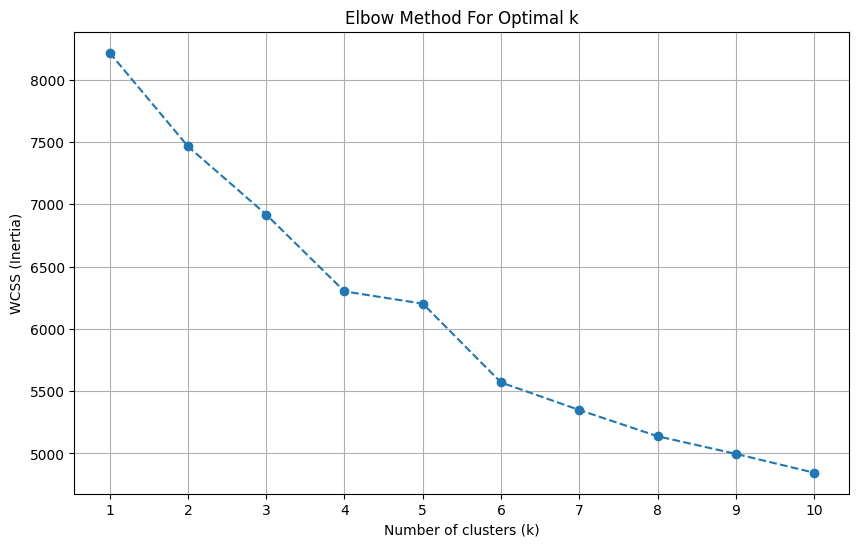

In [ ]:
# Import KMeans
from sklearn.cluster import KMeans

# Determine the optimal number of clusters using the Elbow Method
wcss = [] # Within-Cluster Sum of Square

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', random_state=42, n_init=10) # n_init is specified to suppress a warning
    kmeans.fit(train_df_x)
    wcss.append(kmeans.inertia_) # Inertia is the WCSS

# Plot the Elbow Method graph
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method For Optimal k')
plt.xlabel('Number of clusters (k)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()


Clusters added to training data:


,meals_served,kitchen_staff,temperature_C,humidity_percent,day_of_week,special_event,past_waste_kg,staff_experience,waste_category,year,month,cluster,food_waste_kg
0,-0.356622,0.251520,0.620850,-0.869865,-1.469557,-0.311314,-1.500514,-0.911538,-1.363084,-1.084805,1.831945,2,-0.572256
1,-0.444171,0.947392,0.601953,0.497817,-0.975516,-0.311314,1.097254,0.297909,-0.367753,-1.084805,-1.154661,0,0.249950
2,-0.427755,1.643263,-0.331051,-0.816160,1.494689,-0.311314,1.125154,0.297909,-0.367753,0.163807,-0.856000,0,0.100051
3,-0.172405,-0.444352,0.455666,1.115439,-1.469557,-0.311314,-0.041412,-0.911538,-0.367753,-1.084805,0.338642,0,-0.052505
4,-0.274545,1.411306,-0.583452,1.089155,0.012566,-0.311314,-1.182487,-0.911538,-1.363084,0.163807,-0.856000,2,-0.625316


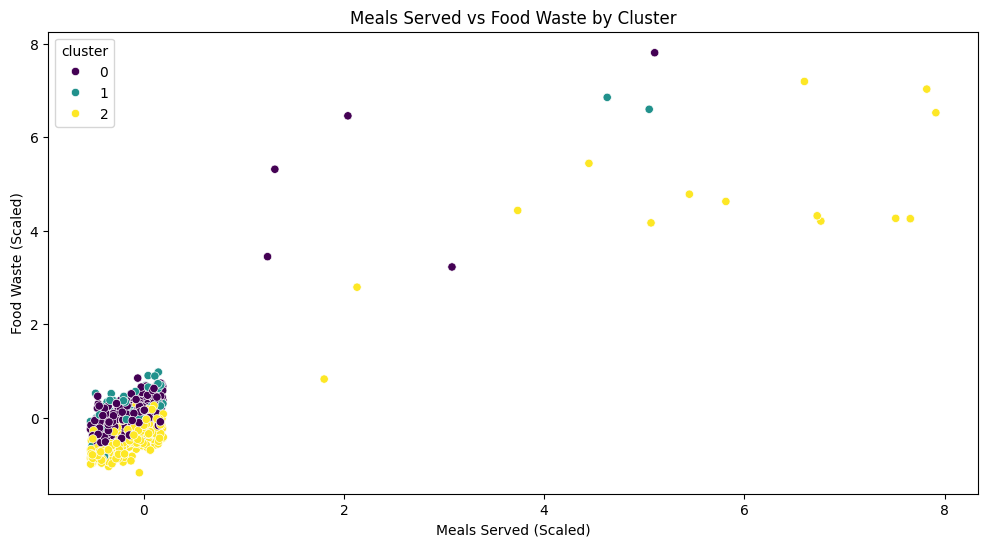

In [ ]:
# Apply K-Means clustering with the chosen number of clusters (e.g., 3)
kmeans = KMeans(n_clusters=3, init='k-means++', random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(train_df_x)

# Add the cluster labels to the training DataFrame
train_df_clustered = train_df_x.copy()
train_df_clustered['cluster'] = cluster_labels

# Add the food_waste_kg column (scaled target variable) back to train_df_clustered for visualization
train_df_clustered['food_waste_kg'] = train_df_y.values

print("Clusters added to training data:")
display(train_df_clustered.head())

# Visualize the clusters (e.g., using a pair plot if feasible or PCA for dimensionality reduction)
# For simplicity, let's visualize a few features against the cluster labels

plt.figure(figsize=(12, 6))
sns.scatterplot(
    x=train_df_clustered['meals_served'],
    y=train_df_clustered['food_waste_kg'], # Use the target variable if available in the original df
    hue=train_df_clustered['cluster'],
    palette='viridis',
    legend='full'
)
plt.title('Meals Served vs Food Waste by Cluster')
plt.xlabel('Meals Served (Scaled)')
plt.ylabel('Food Waste (Scaled)')
plt.show()